## Содержание
1. Импорт библиотек
2. Загрузка и первичный осмотр данных
3. Очистка данных (Data Cleaning)
4. Создание признаков
5. Анализ временных паттернов
6. Сегментация магазинов
7. Анализ маркетинговых активностей
8. Влияние конкуренции
9. Корреляционный анализ
10. Проверка бизнес-гипотез
11. Ключевые выводы и рекомендации

## Импорт библиотек

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Загрузка и первичный осмотр данных

In [2]:
store = pd.read_csv("C:/rossmann-sales-analytics/data/store.csv")
data = pd.read_csv("C:/rossmann-sales-analytics/data/train.csv")

C:\Users\Huawei\AppData\Local\Temp\ipykernel_12176\2869823330.py:2: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("C:/rossmann-sales-analytics/data/train.csv")


#### Описание колонок

* **Таблица `Store`**: \
`Store` - Идентификатор магазина \
`StoreType`	- Тип магазина \
`Assortment` - Уровень ассортимента (a-обычный, b-средний, с-увеличенный) \
`CompetitionDistance` - Расстояние в метрах до ближайшего магазина-конкурента \
`CompetitionOpenSinceMonth` - Месяц (1-12), когда открылся ближайший конкурент \
`CompetitionOpenSinceYear` - Год, когда открылся ближайший конкурент \
`Promo2` - Участвует ли магазин в долгосрочной непрерывной промо-программе: (1 = да, 0 = нет) \
`Promo2SinceWeek` - Номер календарной недели (1-53), когда магазин начал участвовать в Promo2 \
`Promo2SinceYear` - Год, когда магазин начал участвовать в Promo2 \
`PromoInterval` - Описывает месяцы, в которые начинается новый цикл Promo2. Например, "Feb,May,Aug,Nov" означает, что промо обновляется в феврале, мае, августе и ноябре 

* **Таблица `Data`**: \
`Store` - Уникальный ID магазина \
`DayOfWeek` - День недели (1 - Понедельник, 7 - Воскресенье) \
`Date` - Дата в формате `ГГГГ-ММ-ДД` \
`Sales` - Выручка магазина за этот день (в евро). Это ваша целевая переменная \
`Customers` - Количество покупателей (чеков/транзакций) за день \
`Open` - Работал ли магазин (1 - открыт, 0 - закрыт) \
`Promo` - Проводилась ли в этот день промоакция (1 - да, 0 - нет) \
`StateHoliday` - Государственный праздник (0 - нет праздника, a - государственный праздник, b - пасхальный понедельник, c - Рождество)\
`SchoolHoliday` - Были ли в этот день закрыты школы (1 - да, 0 - нет)

### **`store`**

In [3]:
store.head().T

,0,1,2,3,4
Store,1,2,3,4,5
StoreType,c,a,a,c,a
Assortment,a,a,a,c,a
CompetitionDistance,1270.0,570.0,14130.0,620.0,29910.0
CompetitionOpenSinceMonth,9.0,11.0,12.0,9.0,4.0
CompetitionOpenSinceYear,2008.0,2007.0,2006.0,2009.0,2015.0
Promo2,0,1,1,0,0
Promo2SinceWeek,NaN,13.0,14.0,NaN,NaN
Promo2SinceYear,NaN,2010.0,2011.0,NaN,NaN
PromoInterval,NaN,"Jan,Apr,Jul,Oct","Jan,Apr,Jul,Oct",NaN,NaN


In [4]:
store.describe().T

,count,mean,std,min,25%,50%,75%,max
Store,1115.0,558.000000,322.017080,1.0,279.5,558.0,836.5,1115.0
CompetitionDistance,1112.0,5404.901079,7663.174720,20.0,717.5,2325.0,6882.5,75860.0
CompetitionOpenSinceMonth,761.0,7.224704,3.212348,1.0,4.0,8.0,10.0,12.0
CompetitionOpenSinceYear,761.0,2008.668857,6.195983,1900.0,2006.0,2010.0,2013.0,2015.0
Promo2,1115.0,0.512108,0.500078,0.0,0.0,1.0,1.0,1.0
Promo2SinceWeek,571.0,23.595447,14.141984,1.0,13.0,22.0,37.0,50.0
Promo2SinceYear,571.0,2011.763573,1.674935,2009.0,2011.0,2012.0,2013.0,2015.0


In [5]:
store.info()

<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   str    
 2   Assortment                 1115 non-null   str    
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    str    
dtypes: float64(5), int64(2), str(3)
memory usage: 87.2 KB


In [6]:
store.dtypes

Store                          int64
StoreType                        str
Assortment                       str
CompetitionDistance          float64
CompetitionOpenSinceMonth    float64
CompetitionOpenSinceYear     float64
Promo2                         int64
Promo2SinceWeek              float64
Promo2SinceYear              float64
PromoInterval                    str
dtype: object

In [7]:
store.isna().sum()

Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

### **`data`**

In [8]:
data.head().T

,0,1,2,3,4
Store,1,2,3,4,5
DayOfWeek,5,5,5,5,5
Date,2015-07-31,2015-07-31,2015-07-31,2015-07-31,2015-07-31
Sales,5263,6064,8314,13995,4822
Customers,555,625,821,1498,559
Open,1,1,1,1,1
Promo,1,1,1,1,1
StateHoliday,0,0,0,0,0
SchoolHoliday,1,1,1,1,1


In [9]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Store,1017209.0,558.429727,321.908651,1.0,280.0,558.0,838.0,1115.0
DayOfWeek,1017209.0,3.998341,1.997391,1.0,2.0,4.0,6.0,7.0
Sales,1017209.0,5773.818972,3849.926175,0.0,3727.0,5744.0,7856.0,41551.0
Customers,1017209.0,633.145946,464.411734,0.0,405.0,609.0,837.0,7388.0
Open,1017209.0,0.830107,0.375539,0.0,1.0,1.0,1.0,1.0
Promo,1017209.0,0.381515,0.485759,0.0,0.0,0.0,1.0,1.0
SchoolHoliday,1017209.0,0.178647,0.383056,0.0,0.0,0.0,0.0,1.0


In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 69.8+ MB


In [11]:
data.isna().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

### Соединение датасетов по ключу `Store`

In [12]:
data.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [13]:
data.shape

(1017209, 9)

In [14]:
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [15]:
data.shape

(1017209, 9)

Добавим в таблицу `data` информацию о каждом магазине из таблицы `store`

In [16]:
df = pd.merge(data, store, left_on='Store', right_on='Store')
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [17]:
df.shape

(1017209, 18)

Закодируем значения признака `Assortment`

In [18]:
assortment_map = {
    'a': 'Обычный',
    'b': 'Средний',
    'c': 'Увеличенный'
}
df['Assortment'] = df['Assortment'].map(assortment_map)
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,Обычный,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,Обычный,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,Обычный,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,Увеличенный,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,Обычный,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [26]:
df.dtypes

Store                          int64
DayOfWeek                      int64
Date                             str
Sales                          int64
Customers                      int64
Open                           int64
Promo                          int64
StateHoliday                  object
SchoolHoliday                  int64
StoreType                        str
Assortment                       str
CompetitionDistance          float64
CompetitionOpenSinceMonth    float64
CompetitionOpenSinceYear     float64
Promo2                         int64
Promo2SinceWeek              float64
Promo2SinceYear              float64
PromoInterval                    str
dtype: object

Исправим тип данных у признака `Date`

In [29]:
df['Date'].value_counts()

Date
2015-07-31    1115
2015-07-30    1115
2015-07-29    1115
2015-07-28    1115
2015-07-27    1115
              ... 
2014-07-05     935
2014-07-04     935
2014-07-03     935
2014-07-02     935
2014-07-01     935
Name: count, Length: 942, dtype: int64

In [30]:
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')

In [32]:
df['Date'].dtype

dtype('<M8[us]')

### Значение признака `StoreType`

В описании датасета не дано расшифровки типов магазинов, посмотрим на распределение других признаков в зависимости от значения `StoreType`

In [19]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,Обычный,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,Обычный,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,Обычный,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,Увеличенный,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,Обычный,29910.0,4.0,2015.0,0,NaN,NaN,NaN


Гипотеза 1: тип магазина обозначает, в насколько проходимых местах он находится \
Гипотеза 2: тип магазина обозначает, как много конкурентов находится поблизости


Распределения расстояний до конкурентов для каждого типа магазина

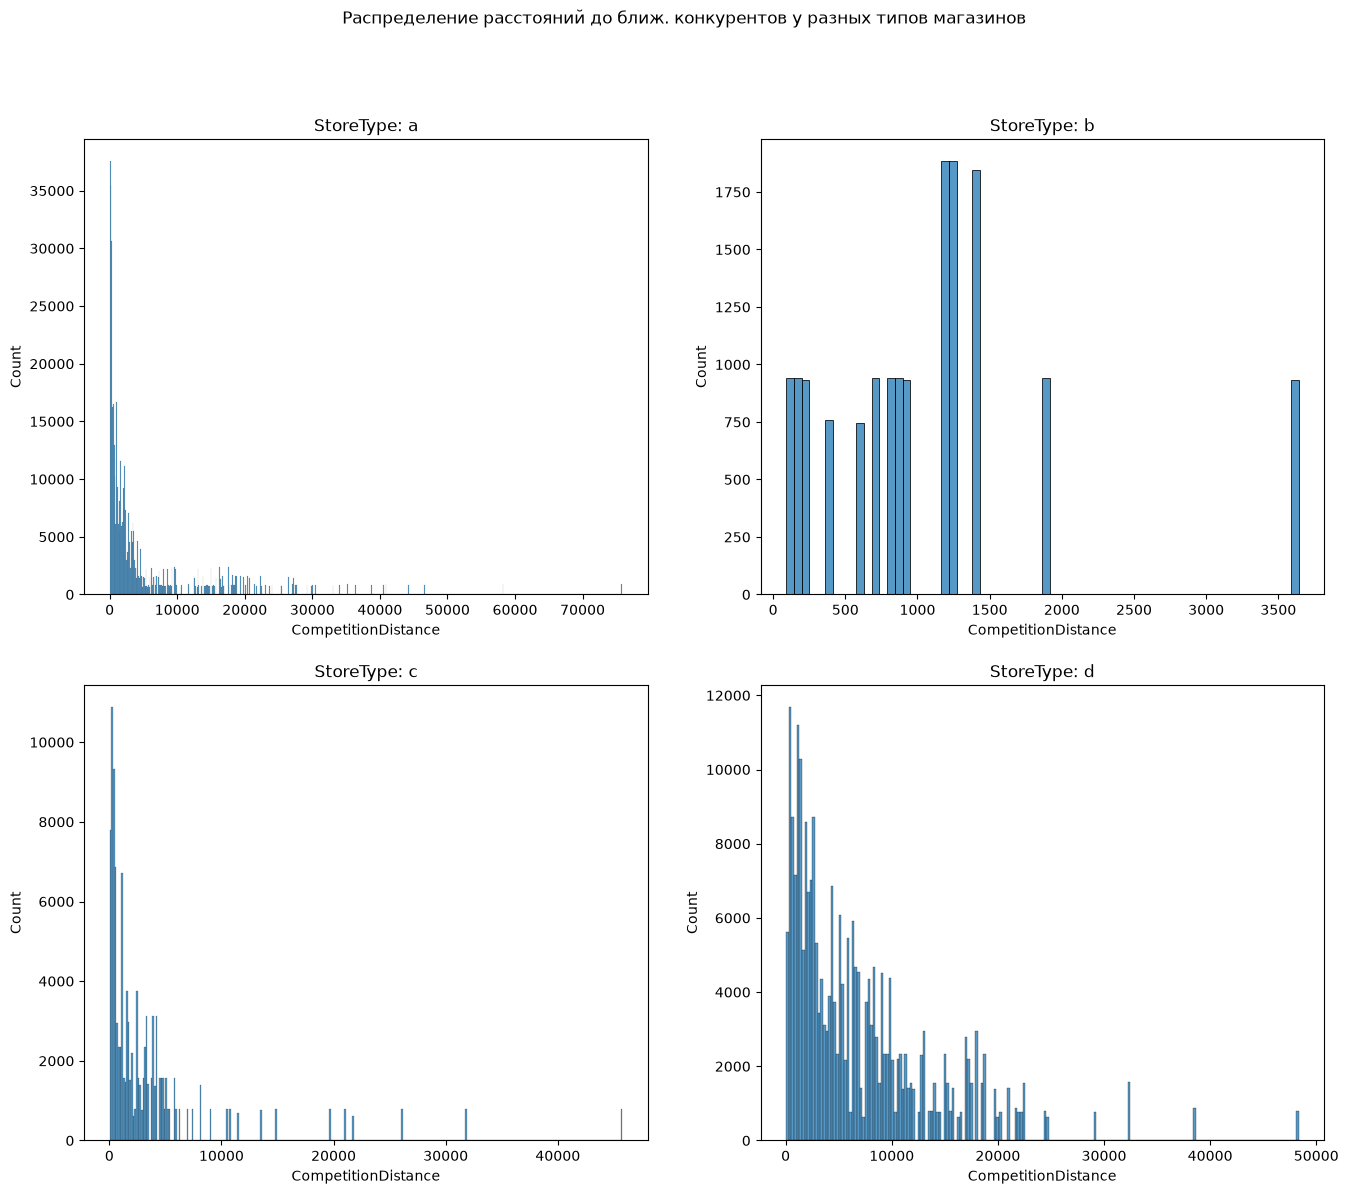

In [20]:
store_types = ['a', 'b', 'c', 'd']

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle("Распределение расстояний до ближ. конкурентов у разных типов магазинов")

cnt = 0
for i in range(0, 2):
    for j in range(0, 2):
        sns.histplot(ax=axes[i, j], data=df[(df['Open'] == 1) & (df['StoreType'] == store_types[cnt])], x='CompetitionDistance')
        axes[i, j].set_title(f'StoreType: {store_types[cnt]}')
        cnt += 1


Распределение кол-ва продаж для каждого типа магазина

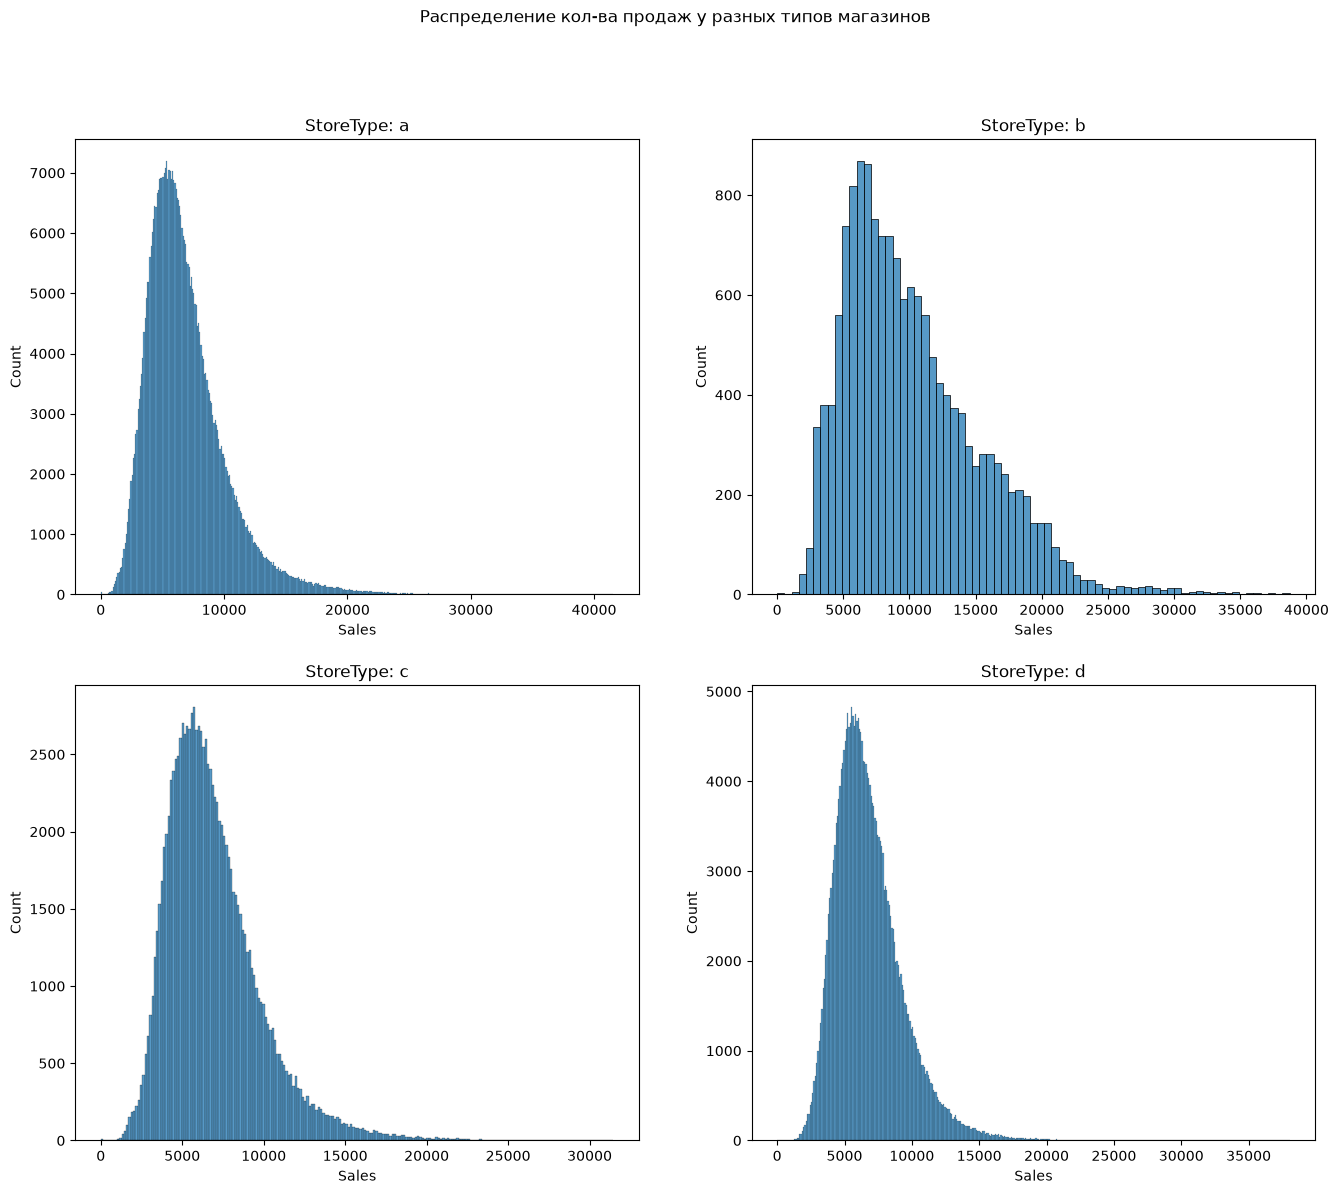

In [21]:
store_types = ['a', 'b', 'c', 'd']

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle("Распределение кол-ва продаж у разных типов магазинов")

cnt = 0
for i in range(0, 2):
    for j in range(0, 2):
        sns.histplot(ax=axes[i, j], data=df[(df['Open'] == 1) & (df['StoreType'] == store_types[cnt])], x='Sales')
        axes[i, j].set_title(f'StoreType: {store_types[cnt]}')
        cnt += 1


Распределение кол-ва покупателей у разных типов магазинов

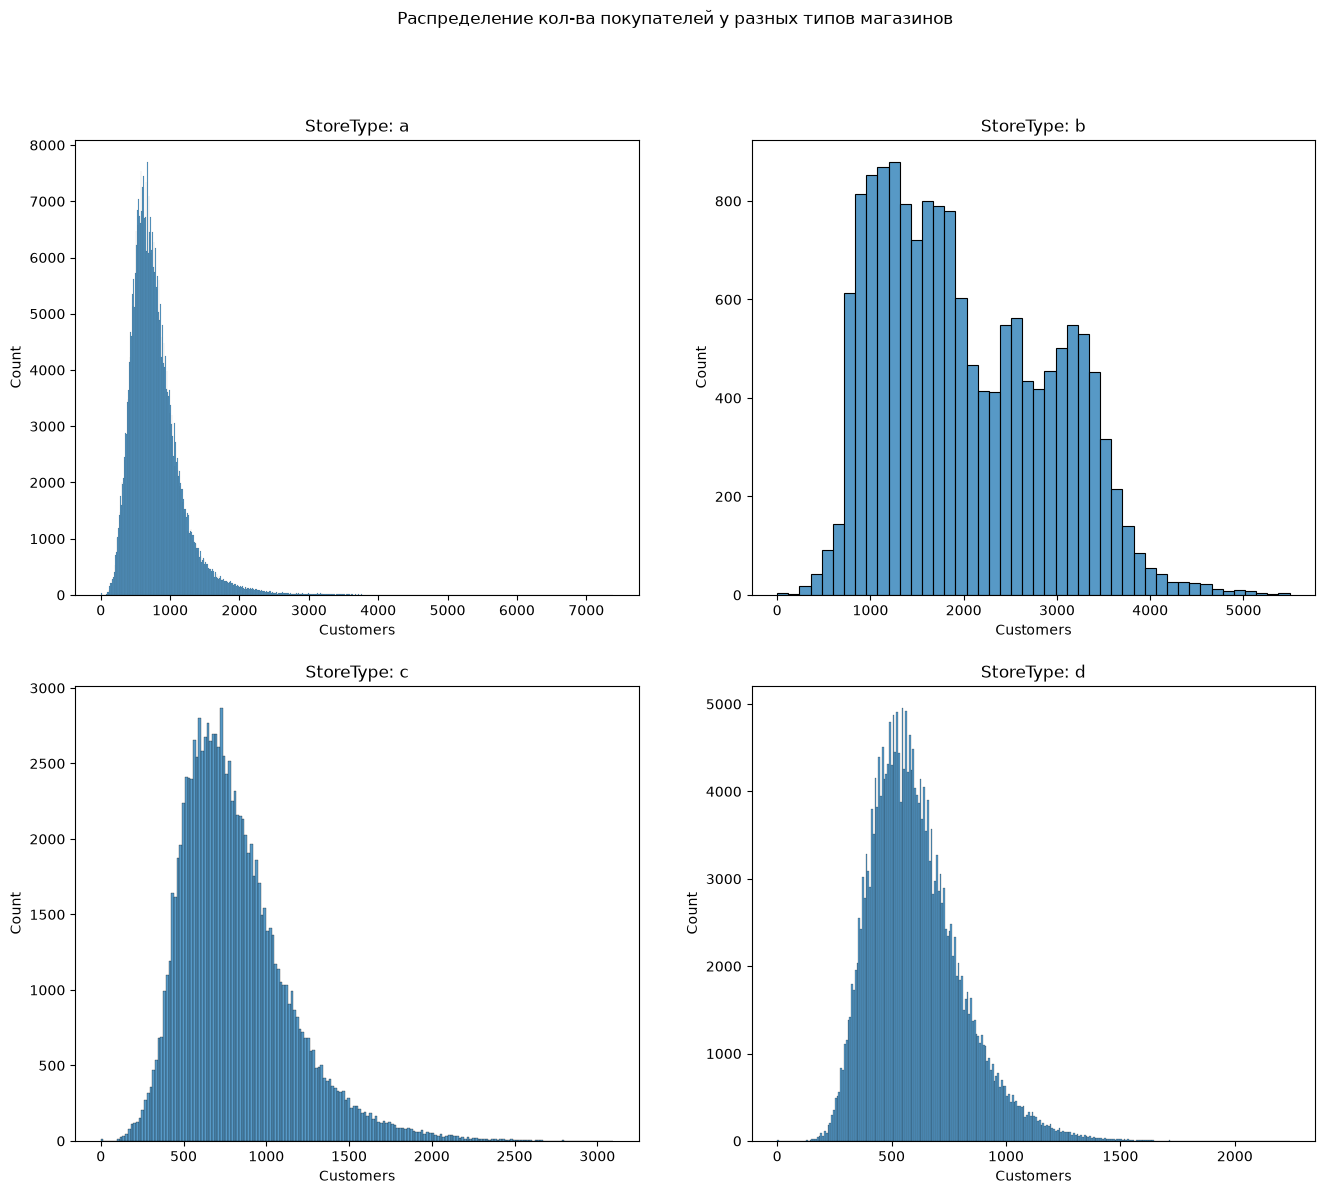

In [22]:
store_types = ['a', 'b', 'c', 'd']

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle("Распределение кол-ва покупателей у разных типов магазинов")

cnt = 0
for i in range(0, 2):
    for j in range(0, 2):
        sns.histplot(ax=axes[i, j], data=df[(df['Open'] == 1) & (df['StoreType'] == store_types[cnt])], x='Customers')
        axes[i, j].set_title(f'StoreType: {store_types[cnt]}')
        cnt += 1


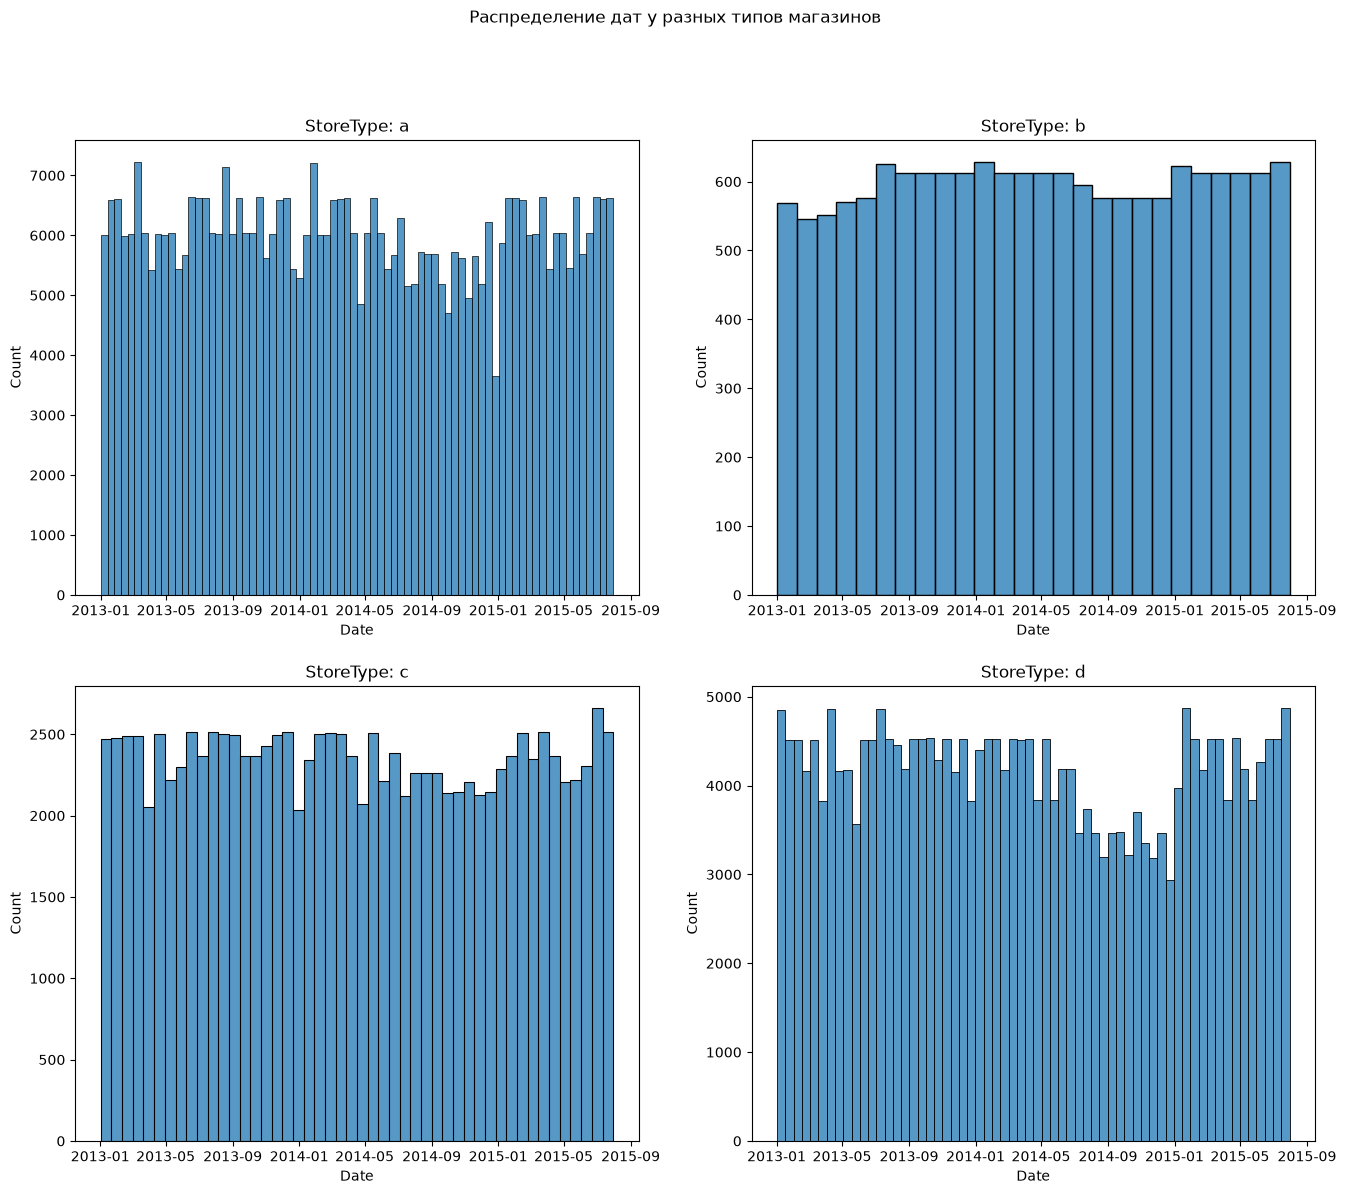

In [33]:
store_types = ['a', 'b', 'c', 'd']

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle("Распределение дат у разных типов магазинов")

cnt = 0
for i in range(0, 2):
    for j in range(0, 2):
        sns.histplot(ax=axes[i, j], data=df[(df['Open'] == 1) & (df['StoreType'] == store_types[cnt])], x='Date')
        axes[i, j].set_title(f'StoreType: {store_types[cnt]}')
        cnt += 1


In [23]:
# Гипотеза 1 не подтвердилась
agg_df = df.groupby('StoreType', as_index=False) \
              .agg({'Sales': 'mean',
                     'Customers': 'mean',
                     'CompetitionDistance': 'mean',
                     }) \
              .rename(
                     columns={'Sales': 'avg_sales',
                            'Customers': 'avg_customers',
                            'CompetitionDistance': 'avg_competition_distance'}) \
              .sort_values('avg_sales', ascending=False)

agg_df['avg_check'] = agg_df['avg_sales'] / agg_df['avg_customers']
agg_df['type_cnt'] = [15830, 551627, 136840, 312912]
agg_df

,StoreType,avg_sales,avg_customers,avg_competition_distance,avg_check,type_cnt
1,b,10058.837334,1987.720846,1066.058117,5.060488,15830
0,a,5738.179710,659.034880,5166.453217,8.706944,551627
2,c,5723.629246,673.265894,3516.699503,8.501291,136840
3,d,5641.819243,501.434892,6959.874812,11.251350,312912


In [ ]:
# Гипотеза 1 не подтвердилась
df.groupby(['StoreType', 'Assortment'], as_index=True) \
                .agg({'Sales': 'count'}) \
                .rename(columns={'Sales': 'cnt'})


cnt
StoreType Assortment         
a         Обычный      346389
          Увеличенный  205238
b         Обычный        6594
          Средний        8294
          Увеличенный     942
c         Обычный       70878
          Увеличенный   65962
d         Обычный      113584
          Увеличенный  199328

In [25]:
df['StoreType'].value_counts(normalize=True)

StoreType
a    0.542295
d    0.307618
c    0.134525
b    0.015562
Name: proportion, dtype: float64

In [ ]:
df[['StoreType', 'Promo']].groupby('StoreType', as_index=False) \
                        .agg({'Promo': 'sum'})

,StoreType,Promo
0,a,210504
1,b,6046
2,c,52244
3,d,119286


In [42]:
df[['Date', 'Promo', 'Promo2']]

,Date,Promo,Promo2
0,2015-07-31,1,0
1,2015-07-31,1,1
2,2015-07-31,1,1
3,2015-07-31,1,0
4,2015-07-31,1,0
...,...,...,...
1017204,2013-01-01,0,1
1017205,2013-01-01,0,0
1017206,2013-01-01,0,0
1017207,2013-01-01,0,0
